In [ ]:
import pandas as pd
import matplotlib.pyplot as plt 

In [ ]:
file=r"file path"#r is givien before to read the file

In [ ]:
Claims=pd.read_excel(file,sheet_name="Claims")#this read claims sheet
Volumes=pd.read_excel(file,sheet_name="Volumes")#this read Volumes sheet

In [ ]:
Volumes=Volumes.iloc[:,1:8]##Just the columsn needed
New_column_names={"Mdl Srs Ds":"Model_Name","Mdl Yr Id":"Model_Year","vin 8 nbr COUNT":"volume_Count","Pro Mo":"Build_Month"} # Adding New column names
Volumes=Volumes.rename(columns=New_column_names)#Renaming column names
Volumes=Volumes.rename(columns={"Model_Year":"MY"})
Volumes=Volumes[Volumes["MY"]>2019]### evaulating only latest MY(2019-CURRENT)
Volumes["Build_year"]=Volumes["Build_Month"].astype(str).str.slice(0,4).astype(int)
Volumes["Build_m"]=Volumes["Build_Month"].astype(str).str.slice(4,6).astype(int)


In [ ]:
Volumes["MIS"]=12*(max(Volumes["Build_year"])-Volumes["Build_year"])-max(Volumes["Build_m"])+Volumes["Build_m"]##calculating MIS with max Buildmonth
Volumes["MY&Build_Month"]=Volumes["MY"].astype(str)+Volumes["Build_Month"].astype(str)##Combining Model year and buildmonth
Volumes = Volumes[Volumes["MY&Build_Month"].astype(float).notnull()]##changing Data type when directly added it adds it cause both or number so conbvert string and change it as number
Volumes["MY&Build_Month"]=Volumes["MY&Build_Month"].astype(int)

In [ ]:
Claims=Claims[[
"Claim Number",
"MY",
"VIN",
"Vehicle Build Date",
"Commodity",
"Vechicle Series Based on model code",
"Technician/Customer Narrative Analysis",
"Total Cost",
"Vehicle Side",
"MIS",
"Repair Date",
"Mileage"
]]
###choosing columns only needed for claims

In [ ]:
######Claims Data Manipulation######

Claims=Claims[Claims["MY"]>2019]#filtering out claims after 2019
Claims["Total Cost"]=Claims["Total Cost"].astype(float)
Claims["MY"]=Claims["MY"].astype(int)#data type integer
Claims["MIS"]=Claims["MIS"].astype(int)#data type int
Claims["Mileage"]=Claims["Mileage"].astype(int)
Claims["Build_Month"]=pd.to_datetime(Claims["Vehicle Build Date"]).dt.strftime('%Y%m')#Adding date(as Year&month)
Claims["MY&Build_Month"]=Claims["MY"].astype(str)+Claims["Build_Month"].astype(str)
Claims["MY&Build_Month"]=Claims["MY&Build_Month"].astype(int)


In [ ]:
Claims.info()

<class 'pandas.DataFrame'>
Index: 18354 entries, 39 to 35485
Data columns (total 14 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   Claim Number                            18354 non-null  object        
 1   MY                                      18354 non-null  int64         
 2   VIN                                     18354 non-null  str           
 3   Vehicle Build Date                      18354 non-null  datetime64[us]
 4   Commodity                               18352 non-null  str           
 5   Vechicle Series Based on model code     18351 non-null  str           
 6   Technician/Customer Narrative Analysis  18354 non-null  str           
 7   Total Cost                              18351 non-null  float64       
 8   Vehicle Side                            18272 non-null  str           
 9   MIS                                     18354 non-null  int64    

In [ ]:
Claims_MY=pd.pivot_table(data=Claims, values="Claim Number", index="MIS", columns="MY",aggfunc='count' )
Claims_MY=Claims_MY.fillna(0)
Claims_MY.reset_index(drop=True, inplace=True)

In [ ]:
Volumes_MY=pd.pivot_table(data=Volumes,values="volume_Count",index="MIS",columns="MY",aggfunc='sum')
Volumes_MY=Volumes_MY.sort_values(by="MIS",ignore_index="True")

In [ ]:
Volumes_MY_1 = pd.DataFrame(index=Volumes_MY.index, columns=Volumes_MY.columns)
for i in range(len(Volumes_MY)):
    Volumes_MY_1.iloc[i]=Volumes_MY.iloc[i:].sum()
Volumes_MY_1 = Volumes_MY_1.astype(int)
Volumes_MY_1.reset_index(drop=True,inplace=True)    

In [ ]:
MIS_IPTV=pd.DataFrame(index=Volumes_MY_1.index, columns=Volumes_MY_1.columns)

In [ ]:
MIS_IPTV=MIS_IPTV.iloc[0:36,1:7]

In [ ]:
for i in MIS_IPTV.index:
    for col in MIS_IPTV.columns:
        denom = Volumes_MY_1.loc[i, col]
        if denom == 0:
            MIS_IPTV.loc[i, col] = 0
        else:
            MIS_IPTV.loc[i, col] = Claims_MY.loc[i, col] * 1000 / denom


In [ ]:
MIS_IPTV_Cum=MIS_IPTV.cumsum()#This cumulative IPTV sum
MIS_IPTV_Cum=MIS_IPTV_Cum.sort_index()###sorting it for 0 to 36MIS

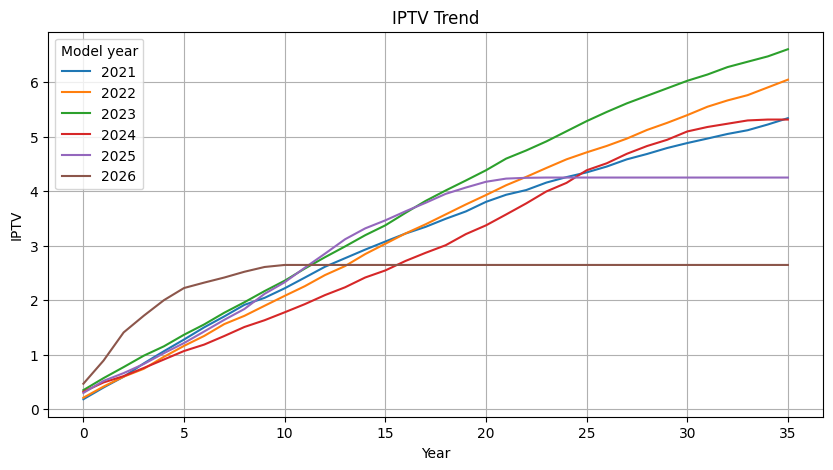

In [ ]:
MIS_IPTV_Cum.plot(figsize=(10,5))
plt.title("IPTV Trend")
plt.xlabel("Year")
plt.ylabel("IPTV")
plt.legend(title="Model year")
plt.grid()
plt.show()

In [ ]:
Claims_MY_Buildmonth=pd.pivot_table(data=Claims, values="Claim Number", index="MY&Build_Month", columns="MIS",aggfunc='count' )
Claims_MY_Buildmonth=Claims_MY_Buildmonth.fillna(0)
Claims_MY_Buildmonth=Claims_MY_Buildmonth.iloc[:,1:38]

In [ ]:
Volumes["MY&Build_Month"]=Volumes["MY&Build_Month"].astype(int)

In [ ]:
Volumes_MY_Buildmonth=pd.pivot_table(data=Volumes,values="volume_Count",index="MY&Build_Month",aggfunc='sum')

In [ ]:
Volumes_MY_Buildmonth_1=pd.DataFrame(index=Volumes_MY_Buildmonth.index,columns=range(37))
for col in range(37):
    Volumes_MY_Buildmonth_1[col] = Volumes_MY_Buildmonth["volume_Count"]

In [ ]:
print("Volumes before:", Volumes_MY_Buildmonth_1.shape)
print("Claims before :", Claims_MY_Buildmonth.shape)

common_index = Volumes_MY_Buildmonth_1.index.intersection(Claims_MY_Buildmonth.index)

Volumes_MY_Buildmonth_1 = Volumes_MY_Buildmonth_1.loc[common_index]
Claims_MY_Buildmonth = Claims_MY_Buildmonth.loc[common_index]

print("Volumes after:", Volumes_MY_Buildmonth_1.shape)
print("Claims after :", Claims_MY_Buildmonth.shape)

Volumes before: (137, 37)
Claims before : (130, 37)
Volumes after: (126, 37)
Claims after : (126, 37)


In [ ]:
print(Volumes_MY_Buildmonth_1.index[:10])
print(Claims_MY_Buildmonth.index[:10])

print(Volumes_MY_Buildmonth_1.index.dtype)
print(Claims_MY_Buildmonth.index.dtype)


Index([2020201905, 2020201906, 2020201907, 2020201908, 2020201909, 2020201910,
       2020201911, 2020201912, 2020202001, 2020202002],
      dtype='int64', name='MY&Build_Month')
Index([2020201905, 2020201906, 2020201907, 2020201908, 2020201909, 2020201910,
       2020201911, 2020201912, 2020202001, 2020202002],
      dtype='int64', name='MY&Build_Month')
int64
int64


In [ ]:
Prod_Month_IPTV = (
    Claims_MY_Buildmonth / Volumes_MY_Buildmonth_1
) * 1000

In [ ]:
Prod_Month_IPTV=Prod_Month_IPTV.cumsum(axis=1)
columns_n=[0,1,6,9,12,18,24,36]
selected_cols = Prod_Month_IPTV.columns[columns_n]
Prod_Month_IPTV = Prod_Month_IPTV[selected_cols]

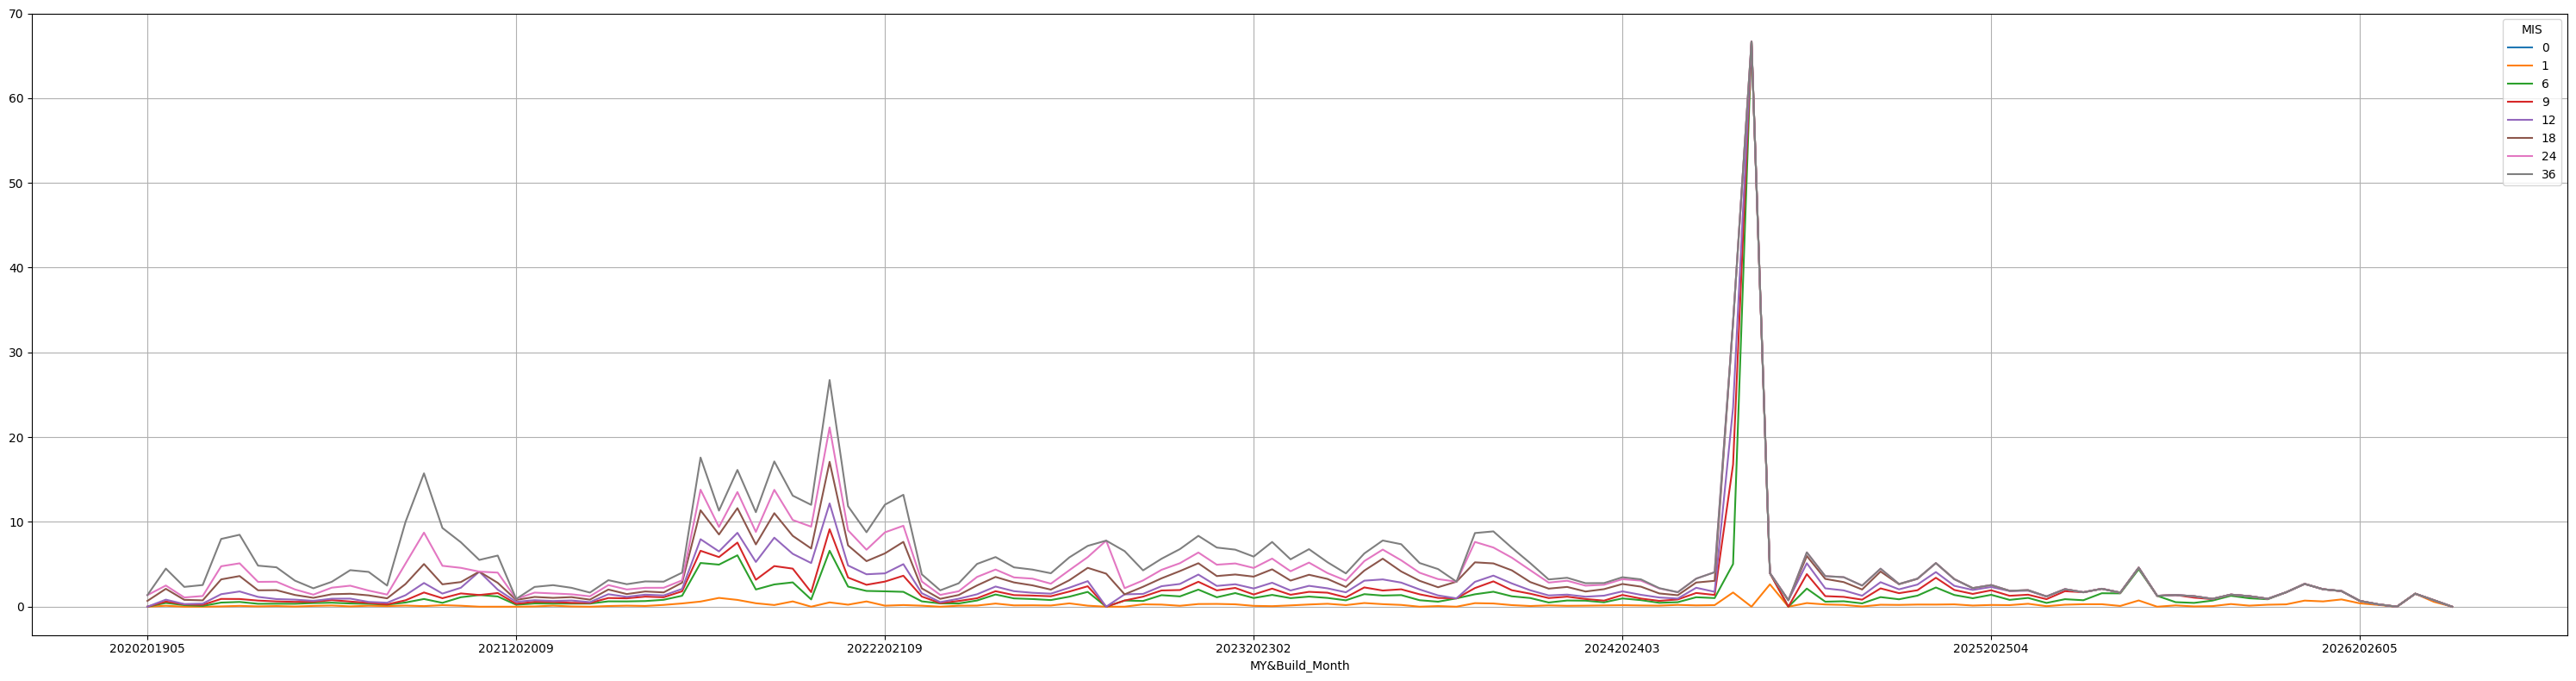

In [ ]:
Prod_Month_IPTV.index = Prod_Month_IPTV.index.astype(str)

ax = Prod_Month_IPTV.plot(figsize=(30, 8))
plt.legend(title="MIS")
plt.grid(True)
plt.tight_layout()
plt.show()